# Ablation Results Visualization Template

This notebook visualizes results from:
- `results/ablation_test_2026-10-07/run_aggregated_summary.csv`
- `results/ablation_test_2026-10-07/per_checkpoint_metrics.csv`

Runs:
- A: Baseline
- B: Mean pooling
- C: Attention pooling
- D: BCE + pos_weight
- E: CNN-only
- F: Random split (baseline model with random split)


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
os.chdir('/home/ray/DeepPallidum')

In [2]:
RESULTS_DIR = 'results/ablation_test_2026-10-07'
AGG_CSV = os.path.join(RESULTS_DIR, 'run_aggregated_summary.csv')
PER_CKPT_CSV = os.path.join(RESULTS_DIR, 'per_checkpoint_metrics.csv')
EPOCH_RUN_CSV = os.path.join(RESULTS_DIR, 'epoch_metrics_by_run.csv')
EPOCH_CKPT_CSV = os.path.join(RESULTS_DIR, 'epoch_metrics_per_checkpoint.csv')

for p in [AGG_CSV, PER_CKPT_CSV, EPOCH_RUN_CSV, EPOCH_CKPT_CSV]:
    if not os.path.exists(p):
        raise FileNotFoundError(f'Missing results file: {p}')

agg = pd.read_csv(AGG_CSV)
per_ckpt = pd.read_csv(PER_CKPT_CSV)
epoch_by_run = pd.read_csv(EPOCH_RUN_CSV)
epoch_per_ckpt = pd.read_csv(EPOCH_CKPT_CSV)

run_name_map = {
    'A_baseline': 'A: Baseline',
    'B_mean_pooling': 'B: Mean pooling',
    'C_attn_pooling': 'C: Attention pooling',
    'D_bce_posweight': 'D: BCE + pos_weight',
    'E_cnn_only': 'E: CNN-only',
    'F_random_split': 'F: Random split',
}

agg['run_label'] = agg['run_id'].map(run_name_map).fillna(agg['run_id'])
per_ckpt['run_label'] = per_ckpt['run_id'].map(run_name_map).fillna(per_ckpt['run_id'])
epoch_by_run['run_label'] = epoch_by_run['run_id'].map(run_name_map).fillna(epoch_by_run['run_id'])
epoch_per_ckpt['run_label'] = epoch_per_ckpt['run_id'].map(run_name_map).fillna(epoch_per_ckpt['run_id'])

run_order = [
    'A_baseline',
    'B_mean_pooling',
    'C_attn_pooling',
    'D_bce_posweight',
    'E_cnn_only',
    'F_random_split',
]

for df in [agg, per_ckpt, epoch_by_run, epoch_per_ckpt]:
    df['run_id'] = pd.Categorical(df['run_id'], categories=run_order, ordered=True)

agg = agg.sort_values('run_id').reset_index(drop=True)
per_ckpt = per_ckpt.sort_values(['run_id', 'checkpoint_name']).reset_index(drop=True)
epoch_by_run = epoch_by_run.sort_values(['run_id', 'epoch']).reset_index(drop=True)
epoch_per_ckpt = epoch_per_ckpt.sort_values(['run_id', 'checkpoint_name', 'epoch']).reset_index(drop=True)


In [3]:
display(agg)
display(per_ckpt.head(15))

,run_id,n_checkpoints,test_macro_f1_mean,test_macro_f1_std,test_micro_f1_mean,test_micro_f1_std,test_macro_pr_auc_mean,test_macro_pr_auc_std,test_exact_match_mean,test_exact_match_std,train_val_ratio_final_mean,train_val_ratio_final_std,run_label
0,A_baseline,3,0.406365,5.510969e-04,0.393543,1.152957e-03,0.376385,0.000496,0.060921,0.006241,2.141581,1.181958e-02,A: Baseline
1,B_mean_pooling,3,0.450659,3.195066e-04,0.441213,7.862618e-04,0.421555,0.001028,0.169126,0.002711,2.320389,2.630840e-02,B: Mean pooling
2,C_attn_pooling,3,0.477189,2.208194e-03,0.469013,1.469436e-03,0.466225,0.000883,0.202660,0.005675,1.786451,2.799165e-02,C: Attention pooling
3,D_bce_posweight,3,0.376306,2.115094e-03,0.367706,1.988117e-03,0.336397,0.001176,0.028504,0.003779,2.029565,2.485127e-02,D: BCE + pos_weight
4,E_cnn_only,3,0.200791,3.399350e-17,0.200905,3.399350e-17,0.111829,0.000000,0.000000,0.000000,0.997157,1.359740e-16,E: CNN-only
5,F_random_split,3,0.383472,6.753388e-04,0.378366,1.537107e-03,0.345766,0.001242,0.068411,0.016889,2.633254,2.275724e-02,F: Random split


,run_id,checkpoint_name,model_name,val_macro_f1,val_micro_f1,val_macro_pr_auc,val_exact_match,test_macro_f1,test_micro_f1,test_macro_pr_auc,test_exact_match,train_val_ratio_final,train_val_ratio_best_f1,run_label
0,A_baseline,dp_catlas_strpal_49k_12_reduced_11_topics_2026...,DeepMSN,0.407264,0.397315,0.353280,0.055436,0.405735,0.392247,0.376528,0.054326,2.141118,1.756670,A: Baseline
1,A_baseline,dp_catlas_strpal_49k_12_reduced_11_topics_2026...,DeepMSN,0.407989,0.398256,0.353036,0.062481,0.406762,0.393928,0.376793,0.061704,2.153626,1.726968,A: Baseline
2,A_baseline,dp_catlas_strpal_49k_12_reduced_11_topics_2026...,DeepMSN,0.404993,0.394276,0.353795,0.064012,0.406596,0.394454,0.375833,0.066734,2.130000,1.761071,A: Baseline
3,B_mean_pooling,dp_catlas_strpal_49k_12_reduced_11_topics_2026...,DeepMSNMeanPooling,0.442318,0.433510,0.396394,0.161715,0.450728,0.440694,0.422741,0.168679,2.294709,2.301393,B: Mean pooling
4,B_mean_pooling,dp_catlas_strpal_49k_12_reduced_11_topics_2026...,DeepMSNMeanPooling,0.440891,0.432100,0.395719,0.164472,0.450938,0.440828,0.420923,0.166667,2.347283,2.296802,B: Mean pooling
5,B_mean_pooling,dp_catlas_strpal_49k_12_reduced_11_topics_2026...,DeepMSNMeanPooling,0.441221,0.432909,0.394985,0.173966,0.450310,0.442118,0.421001,0.172032,2.319174,2.237356,B: Mean pooling
6,C_attn_pooling,dp_catlas_strpal_49k_12_reduced_11_topics_attn...,DeepMSNAttnPooling,0.473100,0.466496,0.453096,0.194487,0.478993,0.469862,0.465335,0.201207,1.804868,1.482588,C: Attention pooling
7,C_attn_pooling,dp_catlas_strpal_49k_12_reduced_11_topics_attn...,DeepMSNAttnPooling,0.474271,0.471640,0.453611,0.212251,0.474727,0.469862,0.466237,0.208920,1.800246,1.496040,C: Attention pooling
8,C_attn_pooling,dp_catlas_strpal_49k_12_reduced_11_topics_attn...,DeepMSNAttnPooling,0.473722,0.466716,0.453950,0.193568,0.477849,0.467317,0.467101,0.197854,1.754240,1.489410,C: Attention pooling
9,D_bce_posweight,dp_catlas_strpal_49k_12_reduced_11_topics_bce_...,DeepMSN,0.383515,0.375849,0.323838,0.027565,0.378736,0.369980,0.336437,0.032864,2.009428,1.967697,D: BCE + pos_weight


## 1) Primary test metrics (mean ± std over 3 seeds)

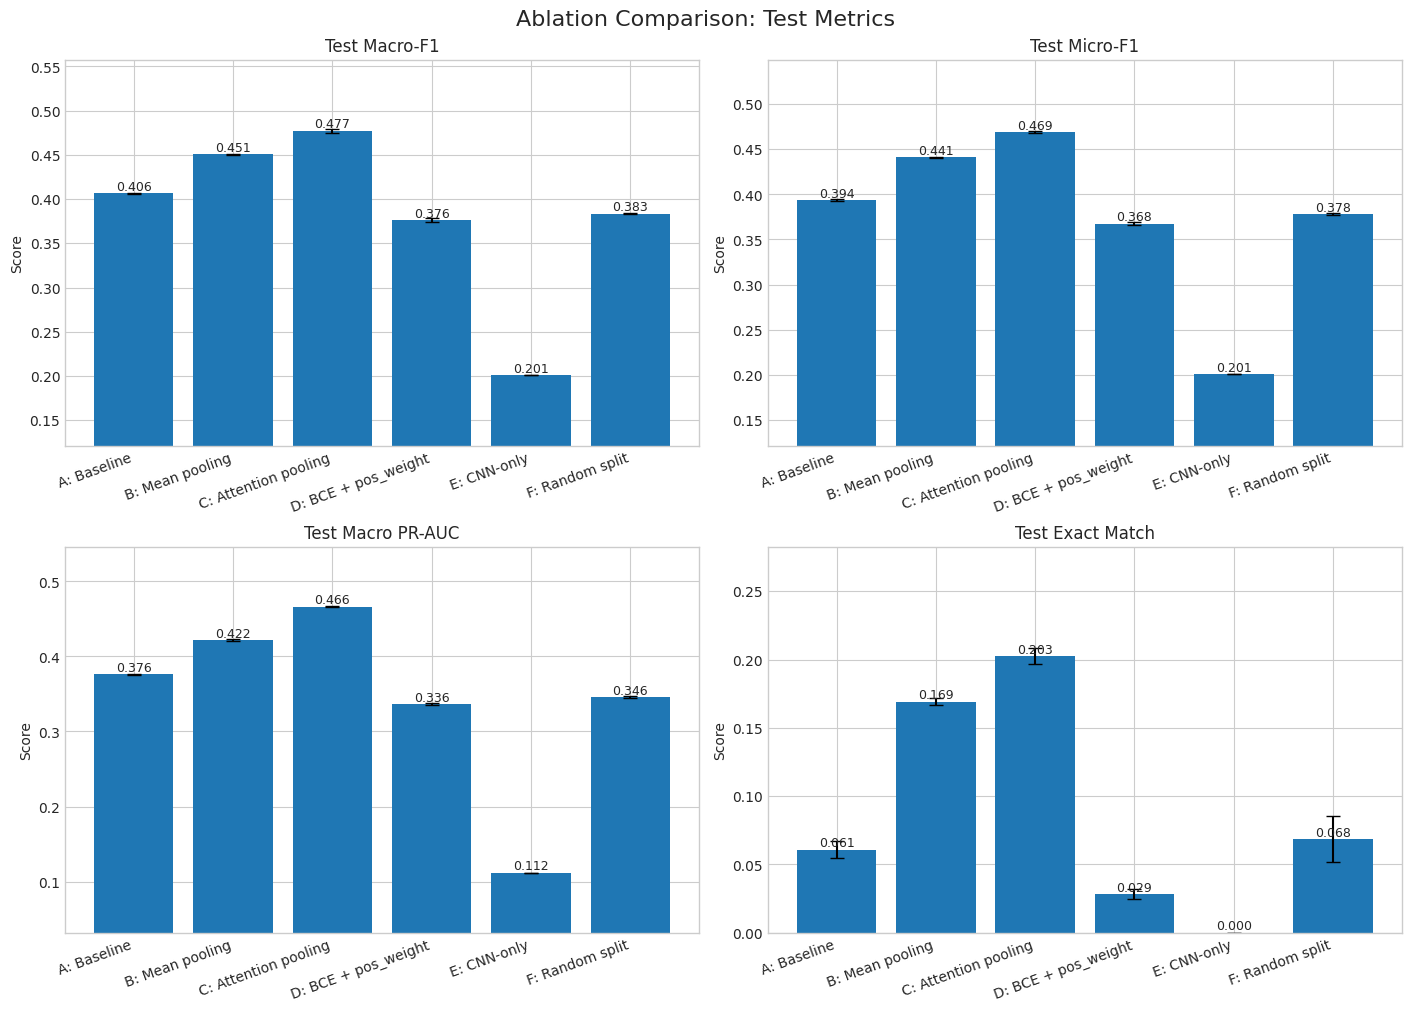

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)

metric_specs = [
    ('test_macro_f1_mean', 'test_macro_f1_std', 'Test Macro-F1'),
    ('test_micro_f1_mean', 'test_micro_f1_std', 'Test Micro-F1'),
    ('test_macro_pr_auc_mean', 'test_macro_pr_auc_std', 'Test Macro PR-AUC'),
    ('test_exact_match_mean', 'test_exact_match_std', 'Test Exact Match'),
]

x = np.arange(len(agg))
labels = agg['run_label'].tolist()

for ax, (mean_col, std_col, title) in zip(axes.flat, metric_specs):
    means = agg[mean_col].to_numpy()
    stds = agg[std_col].to_numpy()
    bars = ax.bar(x, means, yerr=stds, capsize=5)
    ax.set_xticks(x, labels, rotation=20, ha='right')
    ax.set_title(title)
    ax.set_ylabel('Score')
    ymin = max(0.0, float(means.min() - 0.08))
    ymax = min(1.0, float(means.max() + 0.08))
    ax.set_ylim(ymin, ymax)
    for b, m in zip(bars, means):
        ax.text(b.get_x() + b.get_width() / 2, m, f'{m:.3f}', ha='center', va='bottom', fontsize=9)

fig.suptitle('Ablation Comparison: Test Metrics', fontsize=16)
plt.show()


## 2) Seed-level distributions (per-checkpoint metrics)

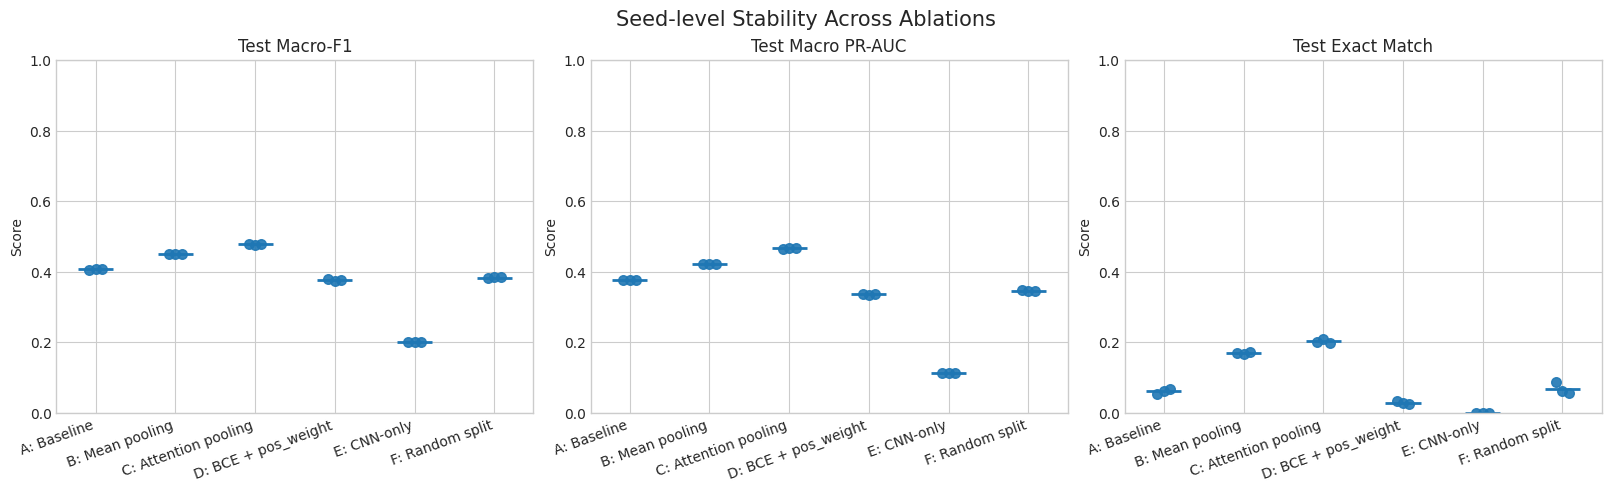

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)
seed_metrics = [
    ('test_macro_f1', 'Test Macro-F1'),
    ('test_macro_pr_auc', 'Test Macro PR-AUC'),
    ('test_exact_match', 'Test Exact Match'),
]

for ax, (col, title) in zip(axes, seed_metrics):
    xs = []
    ys = []
    for i, rid in enumerate(run_order):
        vals = per_ckpt.loc[per_ckpt['run_id'] == rid, col].to_numpy()
        jitter = np.linspace(-0.08, 0.08, num=len(vals)) if len(vals) > 1 else np.array([0.0])
        xvals = np.full_like(vals, i, dtype=float) + jitter
        xs.append(xvals)
        ys.append(vals)
        if len(vals) > 0:
            ax.hlines(vals.mean(), i - 0.22, i + 0.22, linewidth=2)

    if xs:
        ax.scatter(np.concatenate(xs), np.concatenate(ys), s=48, alpha=0.9)
    ax.set_xticks(np.arange(len(run_order)), [run_name_map[r] for r in run_order], rotation=20, ha='right')
    ax.set_title(title)
    ax.set_ylabel('Score')
    ax.set_ylim(0, 1)

fig.suptitle('Seed-level Stability Across Ablations', fontsize=15)
plt.show()

## 3) Generalization profile: performance vs train/val ratio

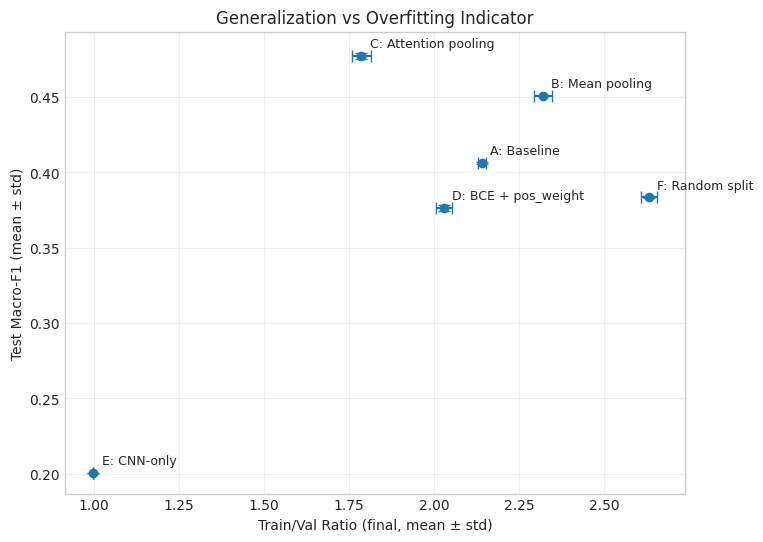

In [6]:
fig, ax = plt.subplots(figsize=(8, 6))

x = agg['train_val_ratio_final_mean'].to_numpy()
y = agg['test_macro_f1_mean'].to_numpy()
xerr = agg['train_val_ratio_final_std'].to_numpy()
yerr = agg['test_macro_f1_std'].to_numpy()

ax.errorbar(x, y, xerr=xerr, yerr=yerr, fmt='o', capsize=4)

for _, row in agg.iterrows():
    ax.annotate(
        row['run_label'],
        (row['train_val_ratio_final_mean'], row['test_macro_f1_mean']),
        textcoords='offset points',
        xytext=(6, 6),
        fontsize=9,
    )
    
ax.set_xlabel('Train/Val Ratio (final, mean ± std)')
ax.set_ylabel('Test Macro-F1 (mean ± std)')
ax.set_title('Generalization vs Overfitting Indicator')
ax.grid(True, alpha=0.3)
plt.show()

## 4) Relative improvement vs baseline (A)

,run_id,run_label,test_macro_f1_mean,test_micro_f1_mean,test_macro_pr_auc_mean,test_exact_match_mean
0,A_baseline,A: Baseline,0.000000,0.000000,0.000000,0.000000
1,B_mean_pooling,B: Mean pooling,0.044294,0.047670,0.045170,0.108205
2,C_attn_pooling,C: Attention pooling,0.070825,0.075470,0.089840,0.141739
3,D_bce_posweight,D: BCE + pos_weight,-0.030059,-0.025837,-0.039987,-0.032417
4,E_cnn_only,E: CNN-only,-0.205574,-0.192638,-0.264556,-0.060921
5,F_random_split,F: Random split,-0.022892,-0.015177,-0.030619,0.007490


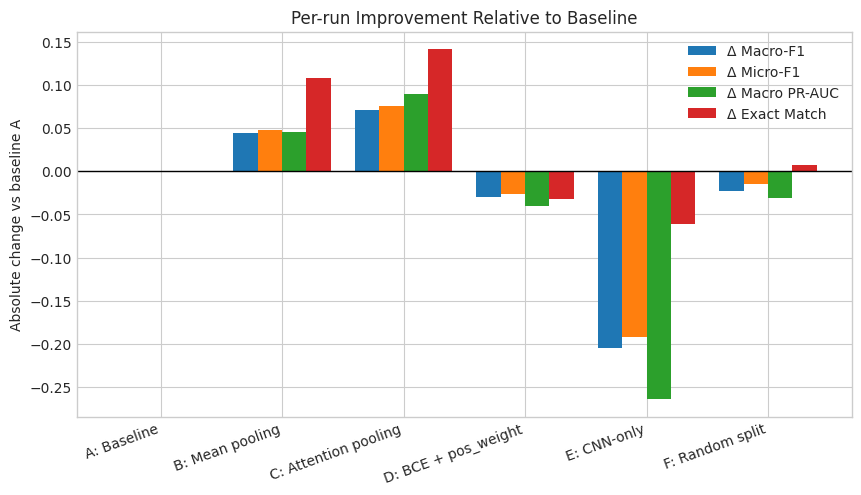

In [7]:
baseline = agg.loc[agg['run_id'] == 'A_baseline'].iloc[0]

compare_cols = [
    'test_macro_f1_mean',
    'test_micro_f1_mean',
    'test_macro_pr_auc_mean',
    'test_exact_match_mean',
]

delta = agg[['run_id', 'run_label'] + compare_cols].copy()
for c in compare_cols:
    delta[c] = delta[c] - baseline[c]

display(delta)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(delta))
w = 0.2

ax.bar(x - 1.5*w, delta['test_macro_f1_mean'], width=w, label='Δ Macro-F1')
ax.bar(x - 0.5*w, delta['test_micro_f1_mean'], width=w, label='Δ Micro-F1')
ax.bar(x + 0.5*w, delta['test_macro_pr_auc_mean'], width=w, label='Δ Macro PR-AUC')
ax.bar(x + 1.5*w, delta['test_exact_match_mean'], width=w, label='Δ Exact Match')

ax.axhline(0, color='black', linewidth=1)
ax.set_xticks(x, delta['run_label'], rotation=20, ha='right')
ax.set_ylabel('Absolute change vs baseline A')
ax.set_title('Per-run Improvement Relative to Baseline')
ax.legend()
plt.show()

## 5) Epoch-wise training dynamics (mean ± std over seeds)


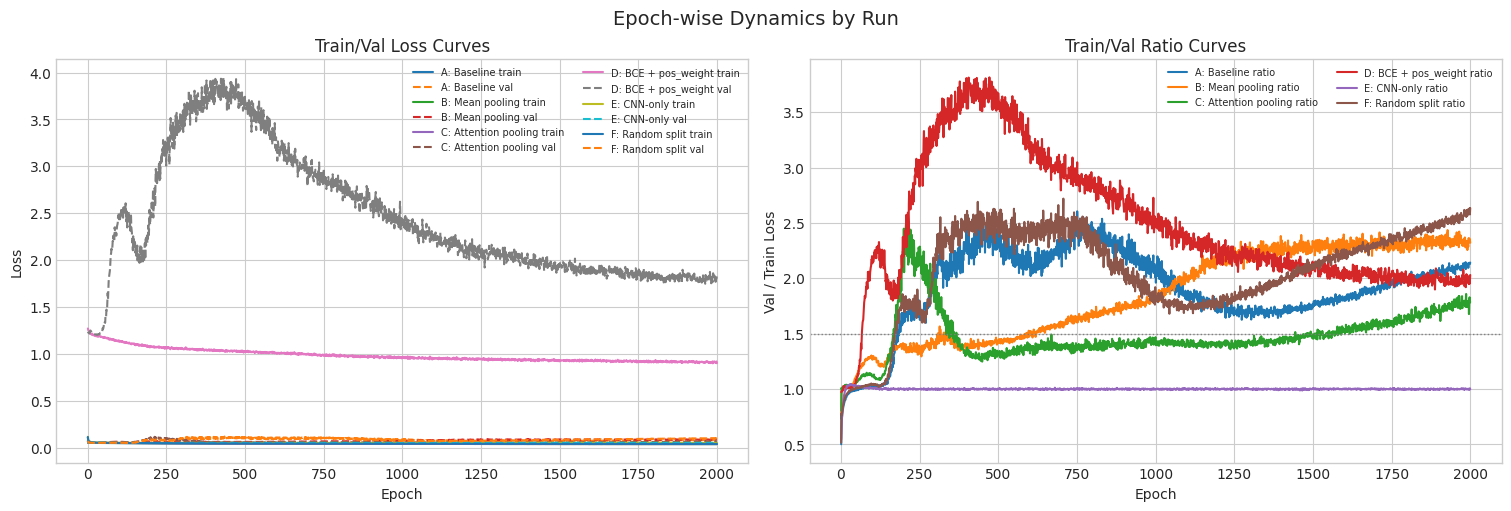

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)

for rid in run_order:
    sub = epoch_by_run[epoch_by_run['run_id'] == rid]
    if sub.empty:
        continue
    label = run_name_map.get(rid, rid)

    axes[0].plot(sub['epoch'], sub['train_loss_mean'], label=f'{label} train')
    axes[0].plot(sub['epoch'], sub['val_loss_mean'], linestyle='--', label=f'{label} val')

    axes[1].plot(sub['epoch'], sub['train_val_ratio_mean'], label=f'{label} ratio')

axes[0].set_title('Train/Val Loss Curves')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend(fontsize=7, ncol=2)

axes[1].set_title('Train/Val Ratio Curves')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Val / Train Loss')
axes[1].axhline(1.5, color='gray', linestyle=':', linewidth=1)
axes[1].legend(fontsize=7, ncol=2)

fig.suptitle('Epoch-wise Dynamics by Run', fontsize=14)
plt.show()


## 6) Focused comparison: F (random split) vs A (chrom split baseline)


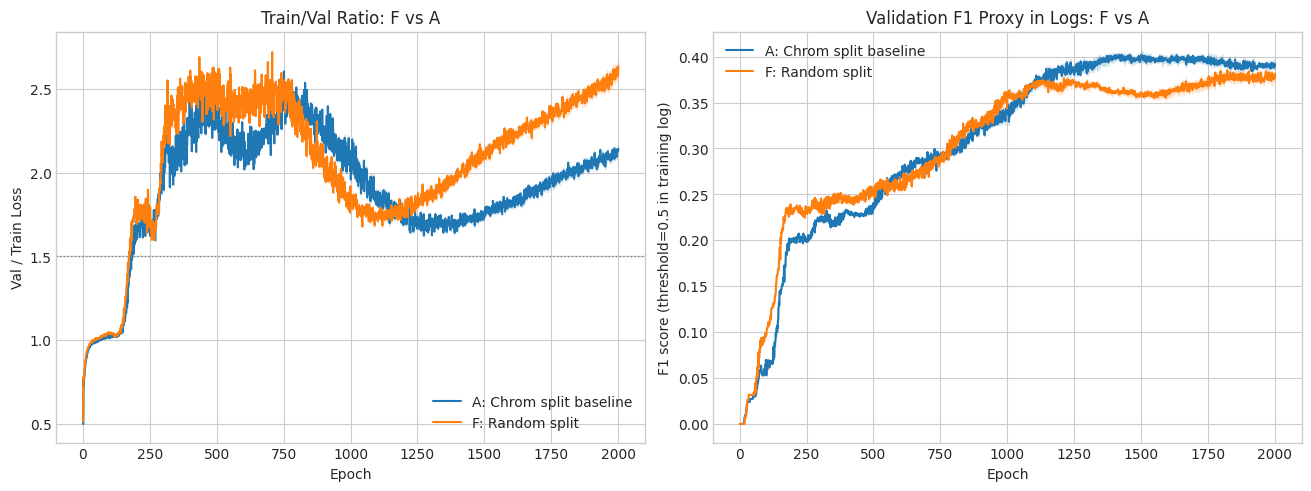

,run_label,test_macro_f1_mean,test_micro_f1_mean,test_macro_pr_auc_mean,test_exact_match_mean,train_val_ratio_final_mean
0,A: Baseline,0.406365,0.393543,0.376385,0.060921,2.141581
5,F: Random split,0.383472,0.378366,0.345766,0.068411,2.633254


F - A deltas:
  Δ test_macro_f1_mean: -0.0229
  Δ test_micro_f1_mean: -0.0152
  Δ test_macro_pr_auc_mean: -0.0306
  Δ test_exact_match_mean: +0.0075
  Δ train_val_ratio_final_mean: +0.4917


In [9]:
a = epoch_by_run[epoch_by_run['run_id'] == 'A_baseline'].copy()
f = epoch_by_run[epoch_by_run['run_id'] == 'F_random_split'].copy()

if a.empty or f.empty:
    raise ValueError('Missing A_baseline or F_random_split in epoch_by_run.csv')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)

for df, label, color in [(a, 'A: Chrom split baseline', 'tab:blue'), (f, 'F: Random split', 'tab:orange')]:
    axes[0].plot(df['epoch'], df['train_val_ratio_mean'], color=color, label=label)
    axes[0].fill_between(
        df['epoch'].to_numpy(),
        (df['train_val_ratio_mean'] - df['train_val_ratio_std']).to_numpy(),
        (df['train_val_ratio_mean'] + df['train_val_ratio_std']).to_numpy(),
        color=color,
        alpha=0.18,
    )

    axes[1].plot(df['epoch'], df['f1_score_mean'], color=color, label=label)
    axes[1].fill_between(
        df['epoch'].to_numpy(),
        (df['f1_score_mean'] - df['f1_score_std']).to_numpy(),
        (df['f1_score_mean'] + df['f1_score_std']).to_numpy(),
        color=color,
        alpha=0.18,
    )

axes[0].set_title('Train/Val Ratio: F vs A')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Val / Train Loss')
axes[0].axhline(1.5, color='gray', linestyle=':', linewidth=1)
axes[0].legend()

axes[1].set_title('Validation F1 Proxy in Logs: F vs A')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('F1 score (threshold=0.5 in training log)')
axes[1].legend()

plt.show()

fa = agg[agg['run_id'].isin(['A_baseline', 'F_random_split'])][[
    'run_label',
    'test_macro_f1_mean',
    'test_micro_f1_mean',
    'test_macro_pr_auc_mean',
    'test_exact_match_mean',
    'train_val_ratio_final_mean',
]].copy()
display(fa)

a_row = fa[fa['run_label'] == 'A: Baseline'].iloc[0]
f_row = fa[fa['run_label'] == 'F: Random split'].iloc[0]
print('F - A deltas:')
print(f"  Δ test_macro_f1_mean: {f_row['test_macro_f1_mean'] - a_row['test_macro_f1_mean']:+.4f}")
print(f"  Δ test_micro_f1_mean: {f_row['test_micro_f1_mean'] - a_row['test_micro_f1_mean']:+.4f}")
print(f"  Δ test_macro_pr_auc_mean: {f_row['test_macro_pr_auc_mean'] - a_row['test_macro_pr_auc_mean']:+.4f}")
print(f"  Δ test_exact_match_mean: {f_row['test_exact_match_mean'] - a_row['test_exact_match_mean']:+.4f}")
print(f"  Δ train_val_ratio_final_mean: {f_row['train_val_ratio_final_mean'] - a_row['train_val_ratio_final_mean']:+.4f}")


## 7) Save figures to `results/ablation_test_2026-10-07/figures`


In [10]:
FIG_DIR = os.path.join(RESULTS_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

print('Tip: Re-run plotting cells and call `fig.savefig(...)` in each cell to export figures here:')
print(FIG_DIR)

Tip: Re-run plotting cells and call `fig.savefig(...)` in each cell to export figures here:
results/ablation_test_2026-10-07/figures


,item,epoch,f1_score,val_loss,train_val_ratio
0,Final epoch,6000,0.500621,0.069599,2.118374
1,Best F1,4929,0.519481,0.068504,2.088901
2,Best val_loss,40,0.044709,0.049823,1.030855


,phase,best_f1,best_val_loss,mean_train_val_ratio
0,1-2000,0.472091,0.049823,1.641751
1,2001-4000,0.518135,0.071529,2.356346
2,4001-end,0.519481,0.067178,2.170290


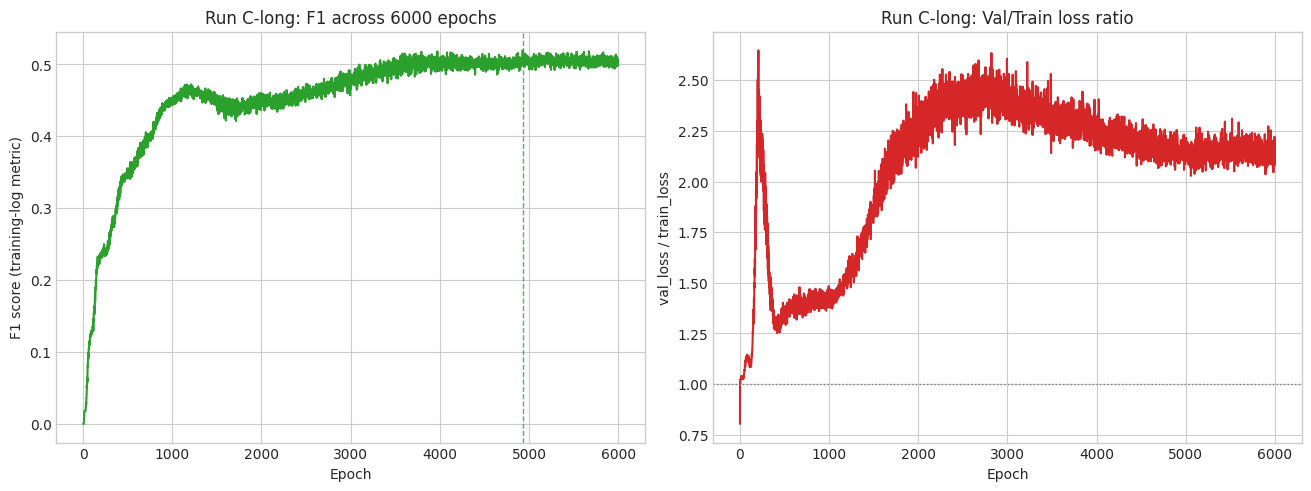

In [11]:
# Run C-long (6000 epochs) follow-up from shared training log snapshot
C_LONG_CANDIDATES = [
    '/home/ray/.vscode-server/data/agentSessionData/eedeff66-bb34-4f1f-9cec-13f9777d6460/attachments/2d7b1c32-776f-4e8f-8664-4e613124cc9a/file_training_log.csv',
    '/home/ray/.vscode-server/data/agentSessionData/eedeff66-bb34-4f1f-9cec-13f9777d6460/attachments/db57c705-445b-4b75-8491-f52650069296/training_log.csv',
]

c_long_csv = next((p for p in C_LONG_CANDIDATES if os.path.exists(p)), None)
if c_long_csv is None:
    raise FileNotFoundError('Could not find C-long training_log.csv in expected attachment paths.')

c_long = pd.read_csv(c_long_csv)
required_cols = {'epoch', 'train_loss', 'val_loss', 'f1_score'}
missing = required_cols - set(c_long.columns)
if missing:
    raise ValueError(f'C-long log missing required columns: {missing}')

c_long = c_long.sort_values('epoch').reset_index(drop=True)
c_long['train_val_ratio'] = c_long['val_loss'] / np.maximum(c_long['train_loss'], 1e-12)

best_f1 = c_long.loc[c_long['f1_score'].idxmax()]
best_val = c_long.loc[c_long['val_loss'].idxmin()]
final_row = c_long.iloc[-1]

phase_1 = c_long[c_long['epoch'].between(1, 2000)]
phase_2 = c_long[c_long['epoch'].between(2001, 4000)]
phase_3 = c_long[c_long['epoch'].between(4001, int(c_long['epoch'].max()))]

phase_summary = pd.DataFrame([
    {'phase': '1-2000', 'best_f1': phase_1['f1_score'].max(), 'best_val_loss': phase_1['val_loss'].min(), 'mean_train_val_ratio': phase_1['train_val_ratio'].mean()},
    {'phase': '2001-4000', 'best_f1': phase_2['f1_score'].max(), 'best_val_loss': phase_2['val_loss'].min(), 'mean_train_val_ratio': phase_2['train_val_ratio'].mean()},
    {'phase': '4001-end', 'best_f1': phase_3['f1_score'].max(), 'best_val_loss': phase_3['val_loss'].min(), 'mean_train_val_ratio': phase_3['train_val_ratio'].mean()},
])

summary = pd.DataFrame([
    {'item': 'Final epoch', 'epoch': int(final_row['epoch']), 'f1_score': final_row['f1_score'], 'val_loss': final_row['val_loss'], 'train_val_ratio': final_row['train_val_ratio']},
    {'item': 'Best F1', 'epoch': int(best_f1['epoch']), 'f1_score': best_f1['f1_score'], 'val_loss': best_f1['val_loss'], 'train_val_ratio': best_f1['train_val_ratio']},
    {'item': 'Best val_loss', 'epoch': int(best_val['epoch']), 'f1_score': best_val['f1_score'], 'val_loss': best_val['val_loss'], 'train_val_ratio': best_val['train_val_ratio']},
])

display(summary)
display(phase_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
axes[0].plot(c_long['epoch'], c_long['f1_score'], color='tab:green')
axes[0].axvline(int(best_f1['epoch']), color='tab:green', linestyle='--', linewidth=1, alpha=0.8)
axes[0].set_title('Run C-long: F1 across 6000 epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('F1 score (training-log metric)')

axes[1].plot(c_long['epoch'], c_long['train_val_ratio'], color='tab:red')
axes[1].axhline(1.0, color='gray', linestyle=':', linewidth=1)
axes[1].set_title('Run C-long: Val/Train loss ratio')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('val_loss / train_loss')

plt.show()
